In [1]:
import os
import pandas as pd

# =========================
# PATHS
# =========================

dbcan_root = "../results/dbcan_hits"

species_dirs = sorted([
    d for d in os.listdir(dbcan_root)
    if os.path.isdir(os.path.join(dbcan_root, d))
])

print(f"Found {len(species_dirs)} species")


Found 30 species


In [2]:
all_hits = []

for species in species_dirs:

    print(f"Processing: {species}")

    domtbl = os.path.join(
        dbcan_root,
        species,
        "dbcan_hits.txt"
    )

    if not os.path.exists(domtbl):
        continue

    with open(domtbl) as f:

        for line in f:

            if line.startswith("#"):
                continue

            parts = line.strip().split()

            if len(parts) < 23:
                continue

            target = parts[0]

            tlen = int(parts[2])

            query = parts[3]

            evalue = float(parts[12])      # i-Evalue
            score = float(parts[13])       # domain score

            hmm_from = int(parts[15])
            hmm_to   = int(parts[16])

            ali_from = int(parts[17])
            ali_to   = int(parts[18])

            coverage = (
                (hmm_to - hmm_from + 1)
                / tlen
            )

            all_hits.append({

                "species": species,

                "query": query,

                "family": target.replace(".hmm", ""),

                "tlen": tlen,

                "evalue": evalue,
                "score": score,

                "hmm_from": hmm_from,
                "hmm_to": hmm_to,

                "ali_from": ali_from,
                "ali_to": ali_to,

                "coverage": coverage
            })

Processing: aspergillus_brasiliensis
Processing: aspergillus_clavatus
Processing: aspergillus_fumigatus
Processing: aspergillus_japonicus
Processing: aspergillus_nidulans
Processing: aspergillus_niger
Processing: aspergillus_oryzae
Processing: aspergillus_terreus
Processing: chaetomium_globosum
Processing: chaetomium_thermophilum
Processing: fusarium_graminearum
Processing: fusarium_oxysporum
Processing: myceliophthora_thermophila
Processing: neurospora_crassa
Processing: penicillium_chrysogenum
Processing: penicillium_digitatum
Processing: penicillium_funiculosum
Processing: penicillium_oxalicum
Processing: penicillium_roqueforti
Processing: pleurotus_ostreatus
Processing: podospora_anserina
Processing: rhizopus_oryzae
Processing: talaromyces_amestolkiae
Processing: talaromyces_pinophilus
Processing: thielavia_terrestris
Processing: trichoderma_atroviride
Processing: trichoderma_harzianum
Processing: trichoderma_reesei
Processing: trichoderma_virens
Processing: yarrowia_lipolytica


In [3]:
hits = pd.DataFrame(all_hits)

print(hits.shape)

hits.head()

(67591, 11)


,species,query,family,tlen,evalue,score,hmm_from,hmm_to,ali_from,ali_to,coverage
0,aspergillus_brasiliensis,tr|A0A1L9U2J4|A0A1L9U2J4_ASPBC,GH16_19,174,4.500000e-73,240.1,2,174,99,272,0.994253
1,aspergillus_brasiliensis,tr|A0A1L9U2J4|A0A1L9U2J4_ASPBC,GH16_18,158,1.100000e-45,150.7,18,158,124,269,0.892405
2,aspergillus_brasiliensis,tr|A0A1L9U2J4|A0A1L9U2J4_ASPBC,GH16_21,207,2.600000e-24,81.6,54,188,118,258,0.652174
3,aspergillus_brasiliensis,tr|A0A1L9U2J4|A0A1L9U2J4_ASPBC,GH16,189,8.600000e-23,77.6,33,184,104,272,0.804233
4,aspergillus_brasiliensis,tr|A0A1L9U2J4|A0A1L9U2J4_ASPBC,GH16_20,163,1.600000e-17,59.4,4,154,108,259,0.926380


In [4]:
hits.describe()

,tlen,evalue,score,hmm_from,hmm_to,ali_from,ali_to,coverage
count,67591.000000,6.759100e+04,67591.000000,67591.000000,67591.000000,67591.000000,67591.000000,67591.000000
mean,334.636845,1.908764e+01,67.382690,84.030137,223.944371,189.280659,335.889068,0.465551
std,167.632679,8.408718e+01,116.458201,114.487131,137.980145,202.103027,211.925052,0.334580
min,21.000000,0.000000e+00,-213.700000,1.000000,2.000000,2.000000,14.000000,0.002532
25%,237.000000,9.750000e-21,9.200000,4.000000,125.000000,60.000000,210.000000,0.161106
50%,301.000000,6.600000e-07,24.600000,29.000000,199.000000,110.000000,290.000000,0.369427
75%,399.000000,3.100000e-02,70.000000,130.000000,294.000000,256.000000,396.000000,0.807171
max,1392.000000,8.800000e+02,1198.600000,1189.000000,1267.000000,2408.000000,2429.000000,1.000000


In [5]:
hits["species"].value_counts()

species
aspergillus_terreus           3145
aspergillus_japonicus         3086
fusarium_oxysporum            3073
aspergillus_brasiliensis      3049
aspergillus_nidulans          3030
aspergillus_fumigatus         2997
aspergillus_niger             2948
penicillium_chrysogenum       2883
fusarium_graminearum          2806
pleurotus_ostreatus           2701
chaetomium_globosum           2630
penicillium_funiculosum       2610
talaromyces_amestolkiae       2560
talaromyces_pinophilus        2484
aspergillus_oryzae            2360
podospora_anserina            2226
penicillium_roqueforti        2209
aspergillus_clavatus          2199
penicillium_oxalicum          2182
myceliophthora_thermophila    2068
trichoderma_atroviride        2063
trichoderma_harzianum         1952
trichoderma_virens            1913
thielavia_terrestris          1781
neurospora_crassa             1773
trichoderma_reesei            1393
penicillium_digitatum         1372
chaetomium_thermophilum       1020
rhizopus_ory

In [6]:
hits["family"].value_counts().head(20)

family
CBM1       878
CBM18      716
AA7        689
CBM50      652
AA3_4      626
AA3_1      590
AA3_3      578
CE1        459
GH5        458
AA9        453
GH74       444
AA1_2      418
GH16_6     412
AA5        412
GH43_18    401
AA1_3      394
PL44       383
GH16       364
GH43_33    363
GH18       357
Name: count, dtype: int64

In [7]:
hits["query"].nunique()

8070

In [8]:
# =========================
# INITIAL FILTERING
# =========================

hits = hits[
    (hits["evalue"] < 1e-15) &
    (hits["coverage"] >= 0.35)
].copy()

hits["class"] = hits["family"].str.extract(
    r"^(GH|GT|PL|CE|AA|CBM)"
)

print(hits.shape)

(19264, 12)


In [9]:
hits.columns

Index(['species', 'query', 'family', 'tlen', 'evalue', 'score', 'hmm_from',
       'hmm_to', 'ali_from', 'ali_to', 'coverage', 'class'],
      dtype='str')

In [10]:
def filter_overlapping_domains(
    df,
    overlap_threshold=0.2
):

    filtered_rows = []

    for protein, group in df.groupby(["species", "query"]):

        group = group.sort_values(
            "score",
            ascending=False
        )

        kept = []

        for _, row in group.iterrows():

            start = row["ali_from"]
            end = row["ali_to"]

            overlap = False

            for kept_row in kept:

                s2 = kept_row["ali_from"]
                e2 = kept_row["ali_to"]

                overlap_len = max(
                    0,
                    min(end, e2) - max(start, s2)
                )

                length = end - start

                if overlap_len / length > overlap_threshold:
                    overlap = True
                    break

            if not overlap:
                kept.append(row)

        filtered_rows.extend(kept)

    return pd.DataFrame(filtered_rows)

In [11]:
def merge_same_family_domains(
    df,
    max_gap=40
):

    merged_rows = []

    for protein, group in df.groupby(["species", "query"]):

        group = group.sort_values("ali_from")

        current = None

        for _, row in group.iterrows():

            if current is None:
                current = row.copy()
                continue

            same_family = (
                row["family"] == current["family"]
            )

            gap = (
                row["ali_from"] -
                current["ali_to"]
            )

            if same_family and gap <= max_gap:

                current["ali_to"] = max(
                    current["ali_to"],
                    row["ali_to"]
                )

            else:
                merged_rows.append(current)
                current = row.copy()

        if current is not None:
            merged_rows.append(current)

    return pd.DataFrame(merged_rows)

In [12]:
hits_filtered = filter_overlapping_domains(hits)

hits_merged = merge_same_family_domains(
    hits_filtered
)

print(len(hits))
print(len(hits_filtered))
print(len(hits_merged))

19264
7096
7042


In [13]:
hits_filtered["query"].nunique()

6362

In [14]:
architecture_df = (
    hits_merged
    .sort_values(
        ["species", "query", "ali_from"]
    )
    .groupby(
        ["species", "query"]
    )["family"]
    .apply(list)
    .reset_index()
)

architecture_df["domain_architecture"] = (
    architecture_df["family"]
    .apply(lambda x: " + ".join(x))
)

architecture_df["domain_count"] = (
    architecture_df["family"]
    .apply(len)
)

architecture_df.head()

,species,query,family,domain_architecture,domain_count
0,aspergillus_brasiliensis,tr|A0A1L9U1H8|A0A1L9U1H8_ASPBC,[AA11],AA11,1
1,aspergillus_brasiliensis,tr|A0A1L9U269|A0A1L9U269_ASPBC,[AA7],AA7,1
2,aspergillus_brasiliensis,tr|A0A1L9U285|A0A1L9U285_ASPBC,[GH171],GH171,1
3,aspergillus_brasiliensis,tr|A0A1L9U287|A0A1L9U287_ASPBC,[AA1],AA1,1
4,aspergillus_brasiliensis,tr|A0A1L9U297|A0A1L9U297_ASPBC,[CE8],CE8,1


In [15]:
architecture_df[
    "domain_architecture"
].value_counts().head(20)

domain_architecture
AA7        390
GH18       289
AA9        274
GH28       230
GH3        217
AA3_2      169
GH76       165
CE5        116
GH16_18    109
CE4        106
GH11       104
GH72        88
AA11        84
CE1         84
GH92        84
GH55_2      81
GH7         80
GH27        77
GH16_1      77
GH31_1      75
Name: count, dtype: int64

In [16]:
multi = architecture_df[
    architecture_df["domain_count"] >= 2
]

multi.sort_values(
    "domain_count",
    ascending=False
)

,species,query,family,domain_architecture,domain_count
2361,fusarium_graminearum,tr|A0A098DKH5|A0A098DKH5_GIBZE,"[CE8, CE8, CE8, CE8, CE8]",CE8 + CE8 + CE8 + CE8 + CE8,5
340,aspergillus_clavatus,tr|A1C8R7|A1C8R7_ASPCL,"[CE8, CE8, CE8, CE8]",CE8 + CE8 + CE8 + CE8,4
1712,aspergillus_terreus,tr|A0A5M3YUF2|A0A5M3YUF2_ASPTE,"[GH79, CBM67, GH78]",GH79 + CBM67 + GH78,3
700,aspergillus_japonicus,tr|A0A8T8WKZ6|A0A8T8WKZ6_ASPJA,"[CE8, CE8, CE8]",CE8 + CE8 + CE8,3
670,aspergillus_fumigatus,tr|B0YAL6|B0YAL6_ASPFC,"[CE8, CE8, CE8]",CE8 + CE8 + CE8,3
...,...,...,...,...,...
373,aspergillus_clavatus,tr|A1CEE2|A1CEE2_ASPCL,"[GH72, CBM43]",GH72 + CBM43,2
385,aspergillus_clavatus,tr|A1CFQ9|A1CFQ9_ASPCL,"[GH13_1, CBM20]",GH13_1 + CBM20,2
386,aspergillus_clavatus,tr|A1CFR0|A1CFR0_ASPCL,"[GH15, CBM20]",GH15 + CBM20,2
388,aspergillus_clavatus,tr|A1CFV0|A1CFV0_ASPCL,"[AA8, AA3_1]",AA8 + AA3_1,2


In [17]:
architecture_df["domain_architecture"].value_counts().head(50)

domain_architecture
AA7              390
GH18             289
AA9              274
GH28             230
GH3              217
AA3_2            169
GH76             165
CE5              116
GH16_18          109
CE4              106
GH11             104
GH72              88
AA11              84
CE1               84
GH92              84
GH55_2            81
GH7               80
GH27              77
GH16_1            77
GH31_1            75
GH128             75
GH5_5             70
AA1               69
GH71              69
CE16              68
GH35              66
GH12              66
GH10              64
CE8               61
GH13_1            61
AA8               60
CE3               58
PL1_4             57
AA1_3             57
GH20              53
GH47              53
AA1_2             53
GH79              53
GH75              52
GH78              50
GH72 + CBM43      49
GH62              49
GH132             49
GH13_22 + GT5     48
GH17              48
GH5_7             47
GH43_6        

In [18]:
architecture_df["domain_architecture"].nunique()

264

In [19]:
species_per_arch = (
    architecture_df
    .groupby("domain_architecture")["species"]
    .nunique()
    .sort_values(ascending=False)
)
species_per_arch.head(20)

domain_architecture
GH72       30
GH3        30
GH16_19    29
GH31_1     29
GH18       29
GH20       29
GH16_1     29
GH47       29
GH76       29
CE8        28
GH11       28
CE4        28
CE16       28
GH13_1     28
AA3_2      28
AA1_2      28
GH28       28
GH16_18    28
AA9        28
GH7        28
Name: species, dtype: int64

In [20]:
multi["domain_architecture"].value_counts().head(50)

domain_architecture
GH72 + CBM43                   49
GH13_22 + GT5                  48
GH71 + CBM24                   34
GH15 + CBM20                   33
GH54 + CBM42                   31
AA8 + AA3_1                    27
GH43_14 + CBM91                19
GH13_1 + CBM20                 18
GH43_36 + CBM91                15
GH55_2 + GH55_2                12
GH7 + CBM1                     11
GH43_29 + CBM6                 11
GH32 + CBM38                    7
GH10 + CBM1                     7
GH43_13 + CBM91                 6
AA13 + CBM20                    5
GH5_4 + CBM46                   5
CE8 + GH28                      5
GH5_5 + CBM1                    4
CBM35 + GH26                    4
CBM87 + CE18                    3
GH12 + GT2_Glycos_transf_2      3
AA1 + AA1                       3
GH18 + CBM24                    3
GH43_34 + CBM66                 3
CE8 + CE8 + CE8                 2
GH142 + CBM13                   2
CBM38 + GH32                    2
GH32 + CBM38 + GH32         

In [21]:
multi["domain_architecture"].nunique()

60

In [22]:
species_per_multi_arch = (
    multi
    .groupby("domain_architecture")["species"]
    .nunique()
    .sort_values(ascending=False)
)
species_per_multi_arch.head(50)

domain_architecture
GH72 + CBM43                   23
GH15 + CBM20                   22
GH54 + CBM42                   20
GH71 + CBM24                   19
GH13_22 + GT5                  17
AA8 + AA3_1                    15
GH13_1 + CBM20                 15
GH43_14 + CBM91                14
GH55_2 + GH55_2                12
GH43_36 + CBM91                10
GH43_29 + CBM6                  9
GH10 + CBM1                     7
GH7 + CBM1                      7
GH43_13 + CBM91                 6
CE8 + GH28                      5
AA13 + CBM20                    5
GH32 + CBM38                    5
GH5_4 + CBM46                   5
CBM35 + GH26                    4
GH5_5 + CBM1                    3
CBM87 + CE18                    3
GH12 + GT2_Glycos_transf_2      3
GH18 + CBM24                    3
GH43_34 + CBM66                 3
AA1 + AA1                       3
GH142 + CBM13                   2
GH128 + GH16_4                  2
GH18 + CBM19                    2
GH11 + CBM1                 

In [23]:
multi_hetero = multi[
    ~multi["domain_architecture"].str.contains(
        r"^(\w+)( \+ \1)+$",
        regex=True
    )
]

C:\Users\Teaholic\AppData\Local\Temp\ipykernel_24580\2381722585.py:2: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  ~multi["domain_architecture"].str.contains(


In [24]:
multi_hetero["domain_architecture"].value_counts().head(50)

domain_architecture
GH72 + CBM43                  49
GH13_22 + GT5                 48
GH71 + CBM24                  34
GH15 + CBM20                  33
GH54 + CBM42                  31
AA8 + AA3_1                   27
GH43_14 + CBM91               19
GH13_1 + CBM20                18
GH43_36 + CBM91               15
GH7 + CBM1                    11
GH43_29 + CBM6                11
GH32 + CBM38                   7
GH10 + CBM1                    7
GH43_13 + CBM91                6
AA13 + CBM20                   5
GH5_4 + CBM46                  5
CE8 + GH28                     5
GH5_5 + CBM1                   4
CBM35 + GH26                   4
CBM87 + CE18                   3
GH12 + GT2_Glycos_transf_2     3
GH18 + CBM24                   3
GH43_34 + CBM66                3
GH142 + CBM13                  2
CBM38 + GH32                   2
GH32 + CBM38 + GH32            2
AA2 + AA5                      2
GH11 + CBM1                    2
GH128 + GH16_4                 2
GH18 + CBM19           

In [25]:
multi_hetero["domain_architecture"].nunique()

51

In [26]:
species_per_multi_hetero_arch = (
    multi_hetero
    .groupby("domain_architecture")["species"]
    .nunique()
    .sort_values(ascending=False)
)
species_per_multi_hetero_arch.head(50)

domain_architecture
GH72 + CBM43                  23
GH15 + CBM20                  22
GH54 + CBM42                  20
GH71 + CBM24                  19
GH13_22 + GT5                 17
AA8 + AA3_1                   15
GH13_1 + CBM20                15
GH43_14 + CBM91               14
GH43_36 + CBM91               10
GH43_29 + CBM6                 9
GH10 + CBM1                    7
GH7 + CBM1                     7
GH43_13 + CBM91                6
AA13 + CBM20                   5
CE8 + GH28                     5
GH32 + CBM38                   5
GH5_4 + CBM46                  5
CBM35 + GH26                   4
CBM87 + CE18                   3
GH43_34 + CBM66                3
GH18 + CBM24                   3
GH12 + GT2_Glycos_transf_2     3
GH5_5 + CBM1                   3
GH76 + CBM13                   2
GH32 + CBM38 + GH32            2
GH11 + CBM1                    2
GH128 + GH16_4                 2
AA2 + AA5                      2
CBM38 + GH32                   2
GH18 + CBM19           

In [27]:
arch_species = pd.crosstab(
    multi_hetero["domain_architecture"],
    multi_hetero["species"]
)
arch_species.sum(axis=1)

domain_architecture
AA13 + CBM20                   5
AA1_3 + AA1                    1
AA2 + AA5                      2
AA8 + AA3_1                   27
AA9 + CBM1                     1
CBM1 + GH10                    1
CBM1 + GH45_1                  1
CBM35 + GH26                   4
CBM38 + GH32                   2
CBM87 + CE18                   3
CE1 + CBM1                     1
CE8 + GH28                     5
GH10 + CBM1                    7
GH11 + CBM1                    2
GH12 + GT2_Glycos_transf_2     3
GH128 + GH16_4                 2
GH13_1 + CBM20                18
GH13_1 + GH13_5                1
GH13_22 + GT5                 48
GH13_32 + CBM20                1
GH142 + CBM13                  2
GH15 + CBM20                  33
GH18 + CBM19                   2
GH18 + CBM24                   3
GH18 + CBM5                    1
GH27 + GH28                    1
GH28 + GH13_8                  1
GH30_7 + GH30                  1
GH30_7 + GT8                   1
GH32 + CBM38           

<Axes: ylabel='domain_architecture'>

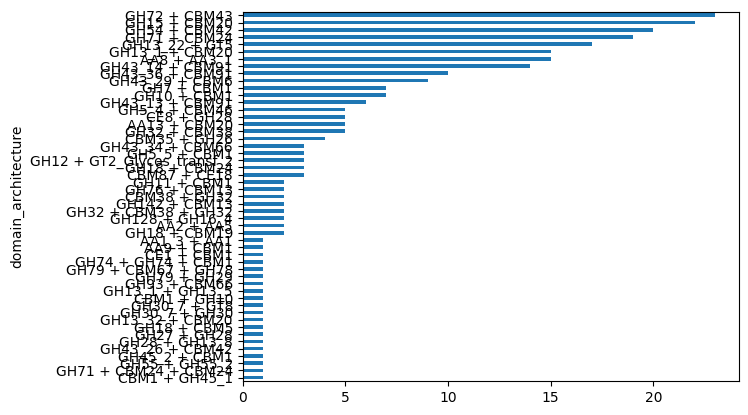

In [28]:
species_per_multi_hetero_arch.sort_values().plot.barh()

In [29]:
# Most common architectures (protein count)
arch_counts = (
    multi_hetero["domain_architecture"]
    .value_counts()
)

common = arch_counts[arch_counts >= 3]

other_count = arch_counts[arch_counts < 3].sum()

arch_counts_plot = pd.concat([
    common,
    pd.Series({"Other rare architectures": other_count})
])

<Axes: >

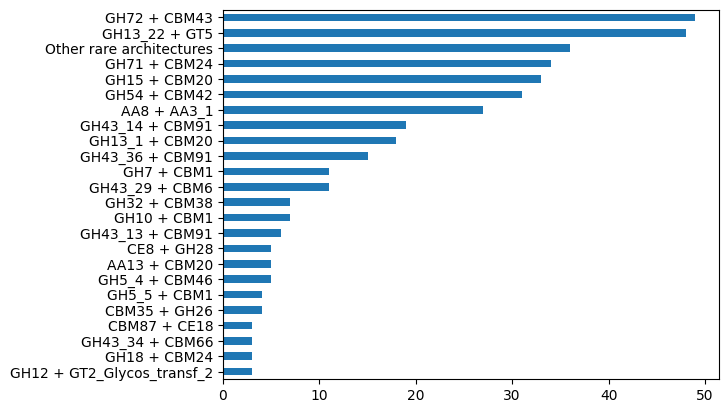

In [30]:
arch_counts_plot.sort_values().plot.barh()

<Axes: >

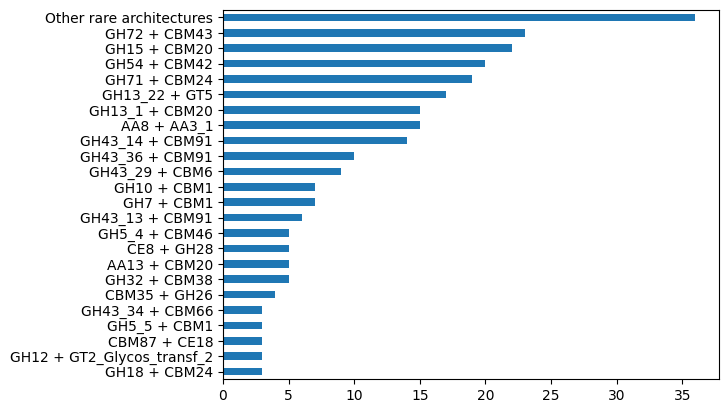

In [31]:
# Most widespread architectures (species count)
common_spec = species_per_multi_hetero_arch[species_per_multi_hetero_arch >= 3]

other_count_spec = species_per_multi_hetero_arch[species_per_multi_hetero_arch < 3].sum()

species_counts_plot = pd.concat([
    common_spec,
    pd.Series({"Other rare architectures": other_count_spec})
])
species_counts_plot.sort_values().plot.barh()

In [32]:
#Which architectures are relevant to biomass degradation?

In [33]:
cellulose_arch = multi_hetero[
    multi_hetero["domain_architecture"]
    .str.contains("CBM")
]

In [34]:
cellulose_arch["domain_architecture"].value_counts()

domain_architecture
GH72 + CBM43            49
GH71 + CBM24            34
GH15 + CBM20            33
GH54 + CBM42            31
GH43_14 + CBM91         19
GH13_1 + CBM20          18
GH43_36 + CBM91         15
GH7 + CBM1              11
GH43_29 + CBM6          11
GH32 + CBM38             7
GH10 + CBM1              7
GH43_13 + CBM91          6
AA13 + CBM20             5
GH5_4 + CBM46            5
GH5_5 + CBM1             4
CBM35 + GH26             4
CBM87 + CE18             3
GH18 + CBM24             3
GH43_34 + CBM66          3
GH142 + CBM13            2
CBM38 + GH32             2
GH32 + CBM38 + GH32      2
GH11 + CBM1              2
GH18 + CBM19             2
GH76 + CBM13             2
GH79 + CBM67 + GH78      1
GH93 + CBM66             1
GH43_26 + CBM42          1
GH13_32 + CBM20          1
AA9 + CBM1               1
CBM1 + GH10              1
CE1 + CBM1               1
GH18 + CBM5              1
CBM1 + GH45_1            1
GH71 + CBM24 + CBM24     1
GH45_2 + CBM1            1
GH74 + G

In [35]:
cellulose_arch["domain_architecture"].nunique()

37

In [36]:
architecture_summary = pd.DataFrame({
    "proteins": multi_hetero["domain_architecture"].value_counts(),
    "species": species_per_multi_hetero_arch
}).reset_index()

architecture_summary.columns = [
    "architecture",
    "proteins",
    "species"
]

architecture_summary = architecture_summary.sort_values(
    "proteins",
    ascending=False
)

architecture_summary.head()

,architecture,proteins,species
45,GH72 + CBM43,49,23
18,GH13_22 + GT5,48,17
43,GH71 + CBM24,34,19
21,GH15 + CBM20,33,22
38,GH54 + CBM42,31,20


In [37]:
biomass_arch = architecture_summary[
    architecture_summary["architecture"].str.contains(
        "GH7|GH6|GH5|GH10|GH11|GH12|GH45|AA9"
    )
]

biomass_arch.head(50)

,architecture,proteins,species
45,GH72 + CBM43,49,23
43,GH71 + CBM24,34,19
38,GH54 + CBM42,31,20
42,GH7 + CBM1,11,7
12,GH10 + CBM1,7,7
40,GH5_4 + CBM46,5,5
41,GH5_5 + CBM1,4,3
14,GH12 + GT2_Glycos_transf_2,3,3
47,GH76 + CBM13,2,2
13,GH11 + CBM1,2,2


In [38]:
interesting_arch = [
    "GH7 + CBM1",
    "GH10 + CBM1",
    "GH5_4 + CBM46",
    "AA9 + CBM1",
    "GH45_2 + CBM1",
    "GH74 + GH74 + CBM1"
]

candidates = multi_hetero[
    multi_hetero["domain_architecture"].isin(
        interesting_arch
    )
]

In [39]:
candidates[
    [
        "species",
        "query",
        "domain_architecture"
    ]
].sort_values(
    ["domain_architecture","species"]
)

,species,query,domain_architecture
4629,podospora_anserina,sp|B2B629|LP9A_PODAN,AA9 + CBM1
520,aspergillus_fumigatus,tr|B0XM69|B0XM69_ASPFC,GH10 + CBM1
1118,aspergillus_nidulans,tr|Q5AWC9|Q5AWC9_EMENI,GH10 + CBM1
3072,myceliophthora_thermophila,tr|G2QJ91|G2QJ91_THET4,GH10 + CBM1
3931,penicillium_funiculosum,tr|T2HRP0|T2HRP0_TALPI,GH10 + CBM1
4728,podospora_anserina,tr|B2AFS1|B2AFS1_PODAN,GH10 + CBM1
5251,talaromyces_amestolkiae,tr|A0A364LCP8|A0A364LCP8_TALAM,GH10 + CBM1
5633,thielavia_terrestris,tr|G2R5G6|G2R5G6_THETT,GH10 + CBM1
5250,talaromyces_amestolkiae,tr|A0A364LCP0|A0A364LCP0_TALAM,GH45_2 + CBM1
611,aspergillus_fumigatus,tr|B0Y1Z4|B0Y1Z4_ASPFC,GH5_4 + CBM46


In [40]:
thermophiles = [
    "myceliophthora_thermophila",
    "thielavia_terrestris",
    "chaetomium_thermophilum"
]

In [41]:
architecture_summary = (
    multi_hetero
    .groupby("domain_architecture")
    .agg(
        proteins=("query", "count"),
        species=("species", "nunique")
    )
    .reset_index()
)

thermo_counts = (
    multi_hetero[
        multi_hetero["species"].isin(thermophiles)
    ]
    .groupby("domain_architecture")["species"]
    .nunique()
    .reset_index(name="thermophile_species")
)

architecture_summary = architecture_summary.merge(
    thermo_counts,
    on="domain_architecture",
    how="left"
)

architecture_summary["thermophile_species"] = (
    architecture_summary["thermophile_species"]
    .fillna(0)
    .astype(int)
)

architecture_summary = architecture_summary.sort_values(
    ["proteins", "species"],
    ascending=False
)

architecture_summary.sort_values("thermophile_species", ascending=False).head(30)

,domain_architecture,proteins,species,thermophile_species
3,AA8 + AA3_1,27,15,3
21,GH15 + CBM20,33,22,2
32,GH43_14 + CBM91,19,14,2
42,GH7 + CBM1,11,7,2
36,GH43_36 + CBM91,15,10,2
7,CBM35 + GH26,4,4,2
16,GH13_1 + CBM20,18,15,2
12,GH10 + CBM1,7,7,2
14,GH12 + GT2_Glycos_transf_2,3,3,2
45,GH72 + CBM43,49,23,1


In [42]:
architecture_summary["has_cbm"] = (
    architecture_summary["domain_architecture"]
    .str.contains("CBM")
)
architecture_summary["has_cellulase"] = (
    architecture_summary["domain_architecture"]
    .str.contains(
        "GH5|GH6|GH7|GH10|GH11|GH12|GH45|AA9"
    )
)
biomass_arch = architecture_summary[
    architecture_summary["has_cellulase"]
]

In [43]:
biomass_arch

,domain_architecture,proteins,species,thermophile_species,has_cbm,has_cellulase
45,GH72 + CBM43,49,23,1,True,True
43,GH71 + CBM24,34,19,1,True,True
38,GH54 + CBM42,31,20,1,True,True
42,GH7 + CBM1,11,7,2,True,True
12,GH10 + CBM1,7,7,2,True,True
40,GH5_4 + CBM46,5,5,0,True,True
41,GH5_5 + CBM1,4,3,0,True,True
14,GH12 + GT2_Glycos_transf_2,3,3,2,False,True
13,GH11 + CBM1,2,2,0,True,True
15,GH128 + GH16_4,2,2,0,False,True


In [44]:
'''gh7_cbm1 = multi_hetero[
    multi_hetero["domain_architecture"] == "GH7 + CBM1"
]

gh10_cbm1 = multi_hetero[
    multi_hetero["domain_architecture"] == "GH10 + CBM1"
]'''

'gh7_cbm1 = multi_hetero[\n    multi_hetero["domain_architecture"] == "GH7 + CBM1"\n]\n\ngh10_cbm1 = multi_hetero[\n    multi_hetero["domain_architecture"] == "GH10 + CBM1"\n]'

In [45]:
# Master architecture table

architecture_summary.to_csv(
    "../results/tables/architecture_summary.csv",
    index=False
)
# Biomass-related architectures

biomass_arch.to_csv(
    "../results/tables/biomass_architectures.csv",
    index=False
)
# Candidate proteins

candidate_proteins = multi_hetero[
    multi_hetero["domain_architecture"].isin(
        biomass_arch["domain_architecture"]
    )
]

candidate_proteins[
    ["species", "query", "domain_architecture"]
].to_csv(
    "../results/tables/candidate_proteins.csv",
    index=False
)

C:\Users\Teaholic\AppData\Local\Temp\ipykernel_24580\2794300293.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\Teaholic\AppData\Local\Temp\ipykernel_24580\2794300293.py:10: UserWarning: The palette list has more values (51) than needed (24), which may not be intended.
  sns.barplot(


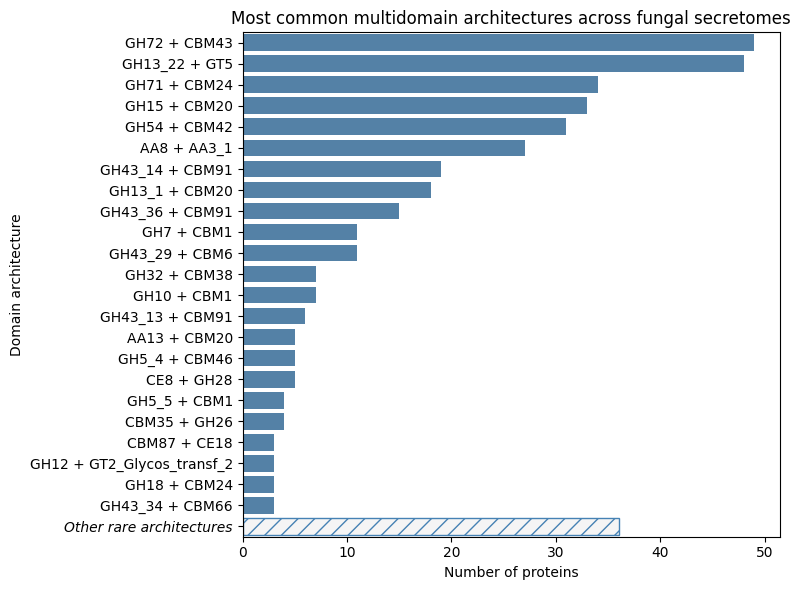

In [77]:
# Figure 2 — Most Common Multidomain Architectures
import matplotlib.pyplot as plt
import seaborn as sns

colors = ["steelblue"] * len(plot_df)
colors[-1] = "lightgray"

plt.figure(figsize=(8,6))

sns.barplot(
    x=arch_counts_plot.values,
    y=arch_counts_plot.index,
    palette=colors
)

ax = plt.gca()

ax.get_yticklabels()[-1].set_style("italic")
#ax.get_yticklabels()[-1].set_color("dimgray")

plt.xlabel("Number of proteins")
plt.ylabel("Domain architecture")
plt.title("Most common multidomain architectures across fungal secretomes")

plt.tight_layout()

ax.patches[-1].set_facecolor("whitesmoke")
ax.patches[-1].set_edgecolor("steelblue")
ax.patches[-1].set_hatch("//")


plt.savefig(
    "../results/figures/multidomain_architecture_frequency.png",
    dpi=300
)

plt.show()

C:\Users\Teaholic\AppData\Local\Temp\ipykernel_24580\2888297373.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\Teaholic\AppData\Local\Temp\ipykernel_24580\2888297373.py:9: UserWarning: The palette list has more values (51) than needed (24), which may not be intended.
  sns.barplot(


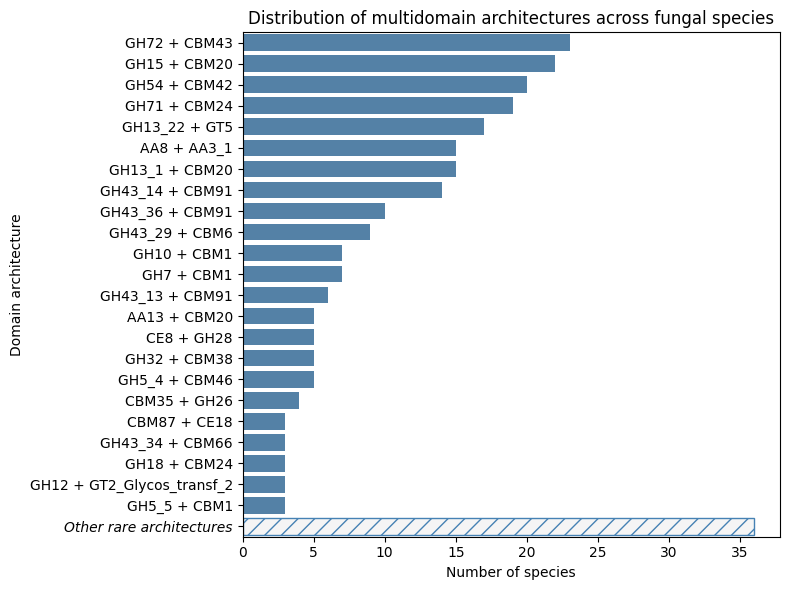

In [78]:
#Figure 3 — Most Widespread Architecturesplt.figure(figsize=(8,6))


colors = ["steelblue"] * len(plot_df)
colors[-1] = "lightgray"

plt.figure(figsize=(8,6))

sns.barplot(
    x=species_counts_plot.values,
    y=species_counts_plot.index,
    palette=colors
)

ax = plt.gca()

ax.get_yticklabels()[-1].set_style("italic")
#ax.get_yticklabels()[-1].set_color("dimgray")

plt.xlabel("Number of species")
plt.ylabel("Domain architecture")
plt.title("Distribution of multidomain architectures across fungal species")

ax.patches[-1].set_facecolor("whitesmoke")
ax.patches[-1].set_edgecolor("steelblue")
ax.patches[-1].set_hatch("//")

plt.tight_layout()

plt.savefig(
    "../results/figures/multidomain_architecture_species_distribution.png",
    dpi=300
)

plt.show()


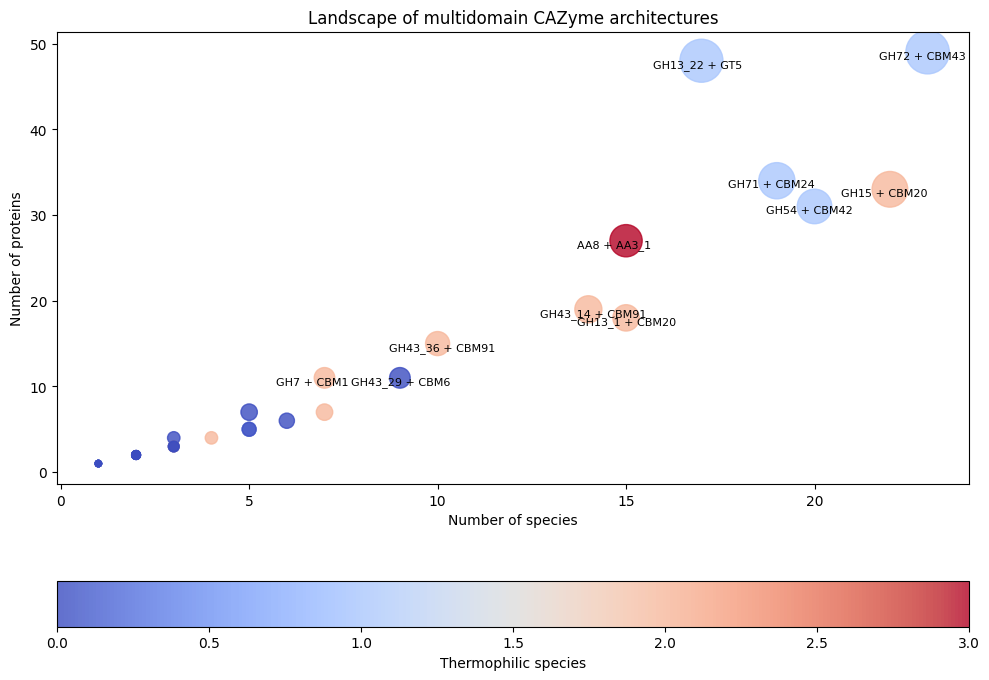

In [100]:
#Figure 4 — Architecture Landscape
plot_df = architecture_summary.copy()

plt.figure(figsize=(10,7))

scatter = plt.scatter(
    plot_df["species"],
    plot_df["proteins"],
    s=plot_df["proteins"] * 20,
    c=plot_df["thermophile_species"],
    cmap="coolwarm",
    alpha=0.8
)

label_df = plot_df[
    plot_df["proteins"] >= 10
]

'''for i, (_, row) in enumerate(label_df.iterrows()):

    offset = 5 if i % 2 == 0 else -10

    plt.annotate(
        row["domain_architecture"],
        (row["species"], row["proteins"]),
        xytext=(5, offset),
        textcoords="offset points",
        fontsize=8
    )'''


for _, row in label_df.iterrows():

    plt.annotate(
        row["domain_architecture"],
        (row["species"], row["proteins"]),
        xytext=(-35,-5),
        textcoords="offset points",
        fontsize=8
    )

plt.xlabel("Number of species")
plt.ylabel("Number of proteins")
#plt.yscale("log")

plt.title(
    "Landscape of multidomain CAZyme architectures"
)

plt.subplots_adjust(right=0.9)

#cbar = plt.colorbar(scatter)
#cbar.set_label("Thermophilic species")

cbar = plt.colorbar(
    scatter,
    orientation="horizontal",
    pad=0.15
)

cbar.set_label("Thermophilic species")

plt.tight_layout()

plt.savefig(
    "../results/figures/multidomain_architecture_landscape.png",
    dpi=300
)

plt.show()